In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import KFold, cross_val_score

## B1 First look
Size, column types and summary statistics.

In [10]:
train = pd.read_csv('C:\\Users\\Rita\\Desktop\\HOUSE-PRICES-ARGISHTI-MARGARIAN\\data\\raw\\train.csv')
test  = pd.read_csv('C:\\Users\\Rita\\Desktop\\HOUSE-PRICES-ARGISHTI-MARGARIAN\\data\\raw\\test.csv')
print(train.shape, test.shape)
print(train.dtypes.value_counts())
train.head()

(1460, 81) (1459, 80)
str        43
int64      35
float64     3
Name: count, dtype: int64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [11]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


## B2 Target: SalePrice
Compare the raw distribution with the log distribution.

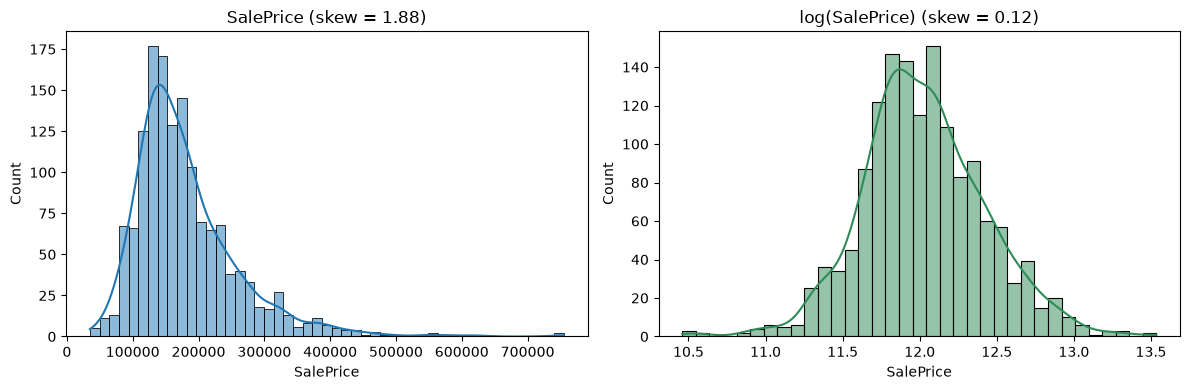

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train['SalePrice'], kde=True, ax=ax[0])
ax[0].set_title(f"SalePrice (skew = {train['SalePrice'].skew():.2f})")
sns.histplot(np.log1p(train['SalePrice']), kde=True, ax=ax[1], color='seagreen')
ax[1].set_title(f"log(SalePrice) (skew = {np.log1p(train['SalePrice']).skew():.2f})")
plt.tight_layout(); plt.savefig('target_distribution.png', dpi=120); plt.show()

## B5 Outliers
Done before cleaning so the plot uses the raw data.

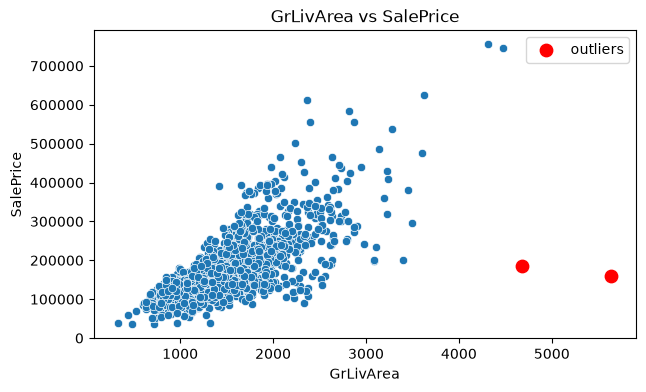

,Id,GrLivArea,SalePrice,SaleCondition
523,524,4676,184750,Partial
1298,1299,5642,160000,Partial


In [13]:
plt.figure(figsize=(7, 4))
sns.scatterplot(data=train, x='GrLivArea', y='SalePrice')
out = train[(train['GrLivArea'] > 4000) & (train['SalePrice'] < 300000)]
plt.scatter(out['GrLivArea'], out['SalePrice'], color='red', s=80, label='outliers')
plt.legend(); plt.title('GrLivArea vs SalePrice')
plt.savefig('outliers_grlivarea.png', dpi=120, bbox_inches='tight'); plt.show()
out[['Id', 'GrLivArea', 'SalePrice', 'SaleCondition']]

In [14]:
train = train.drop(out.index).reset_index(drop=True)
print('Train after removing outliers:', train.shape)

Train after removing outliers: (1458, 81)


**Decision:** remove the 2 houses with >4000 sq ft that sold for under $300k. Both are `Partial` sales, i.e. not normal market prices, and the dataset author (De Cock, 2011) recommends removing them. They would pull the regression line down. Removed from **train only**, because Kaggle needs a prediction for every test house. Nothing else is removed, since with ~1460 rows every real sale is valuable.

## B3 Missing values

In [15]:
def missing_table(df):
    m = df.isnull().sum()
    m = m[m > 0].sort_values(ascending=False)
    return pd.DataFrame({'missing': m, 'percent': (100 * m / len(df)).round(1)})

y = np.log1p(train['SalePrice'])
train_ids, test_ids = train['Id'], test['Id']
all_data = pd.concat([train.drop(columns=['SalePrice']), test], ignore_index=True)
n_train = len(train)
missing_table(all_data)

,missing,percent
PoolQC,2908,99.7
MiscFeature,2812,96.4
Alley,2719,93.2
Fence,2346,80.4
MasVnrType,1766,60.5
FireplaceQu,1420,48.7
LotFrontage,486,16.7
GarageQual,159,5.5
GarageYrBlt,159,5.5
GarageCond,159,5.5


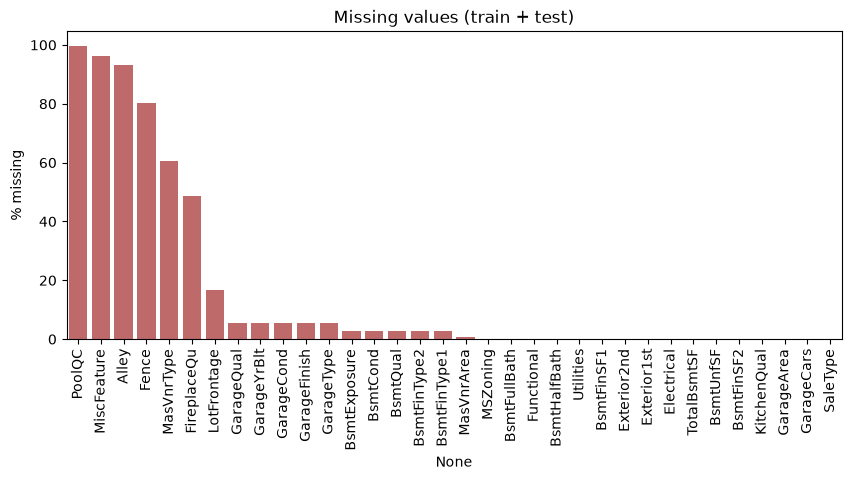

In [16]:
m = missing_table(all_data)
plt.figure(figsize=(10, 4))
sns.barplot(x=m.index, y=m['percent'], color='indianred')
plt.xticks(rotation=90); plt.ylabel('% missing'); plt.title('Missing values (train + test)')
plt.savefig('missing_values.png', dpi=120, bbox_inches='tight'); plt.show()

In [17]:
none_cols = ['PoolQC', 'MiscFeature', 'Alley', 'Fence', 'FireplaceQu',
             'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
             'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
             'MasVnrType']
zero_cols = ['GarageYrBlt', 'GarageArea', 'GarageCars',
             'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
             'BsmtFullBath', 'BsmtHalfBath', 'MasVnrArea']
mode_cols = ['MSZoning', 'Electrical', 'KitchenQual', 'Exterior1st',
             'Exterior2nd', 'SaleType', 'Functional']

for i in none_cols:
    all_data[i] = all_data[i].fillna('None')
for i in zero_cols:
    all_data[i] = all_data[i].fillna(0)
for i in mode_cols:
    all_data[i] = all_data[i].fillna(all_data[i].iloc[:n_train].mode()[0])

lf_median = all_data.iloc[:n_train].groupby('Neighborhood')['LotFrontage'].median()
all_data['LotFrontage'] = all_data['LotFrontage'].fillna(all_data['Neighborhood'].map(lf_median))

all_data = all_data.drop(columns=['Utilities'])
print('Missing values left:', all_data.isnull().sum().sum())
assert all_data.isnull().sum().sum() == 0

Missing values left: 0


## B4 Visualizations
### Numeric features: correlation with SalePrice

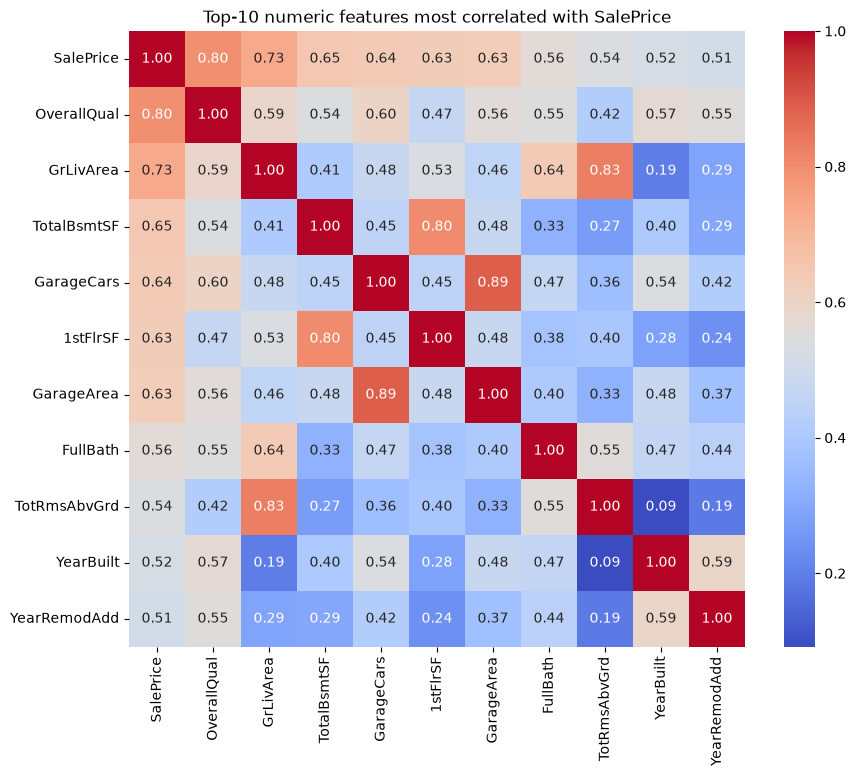

In [18]:
tr = all_data.iloc[:n_train].copy()
tr['SalePrice'] = train['SalePrice'].values
num = tr.select_dtypes(include=np.number).drop(columns='Id')
top = num.corr()['SalePrice'].abs().sort_values(ascending=False).index[:11]
plt.figure(figsize=(10, 8))
sns.heatmap(num[top].corr(), annot=True, fmt='.2f', cmap='coolwarm', square=True)
plt.title('Top-10 numeric features most correlated with SalePrice')
plt.savefig('correlation_heatmap.png', dpi=120, bbox_inches='tight')
plt.show()

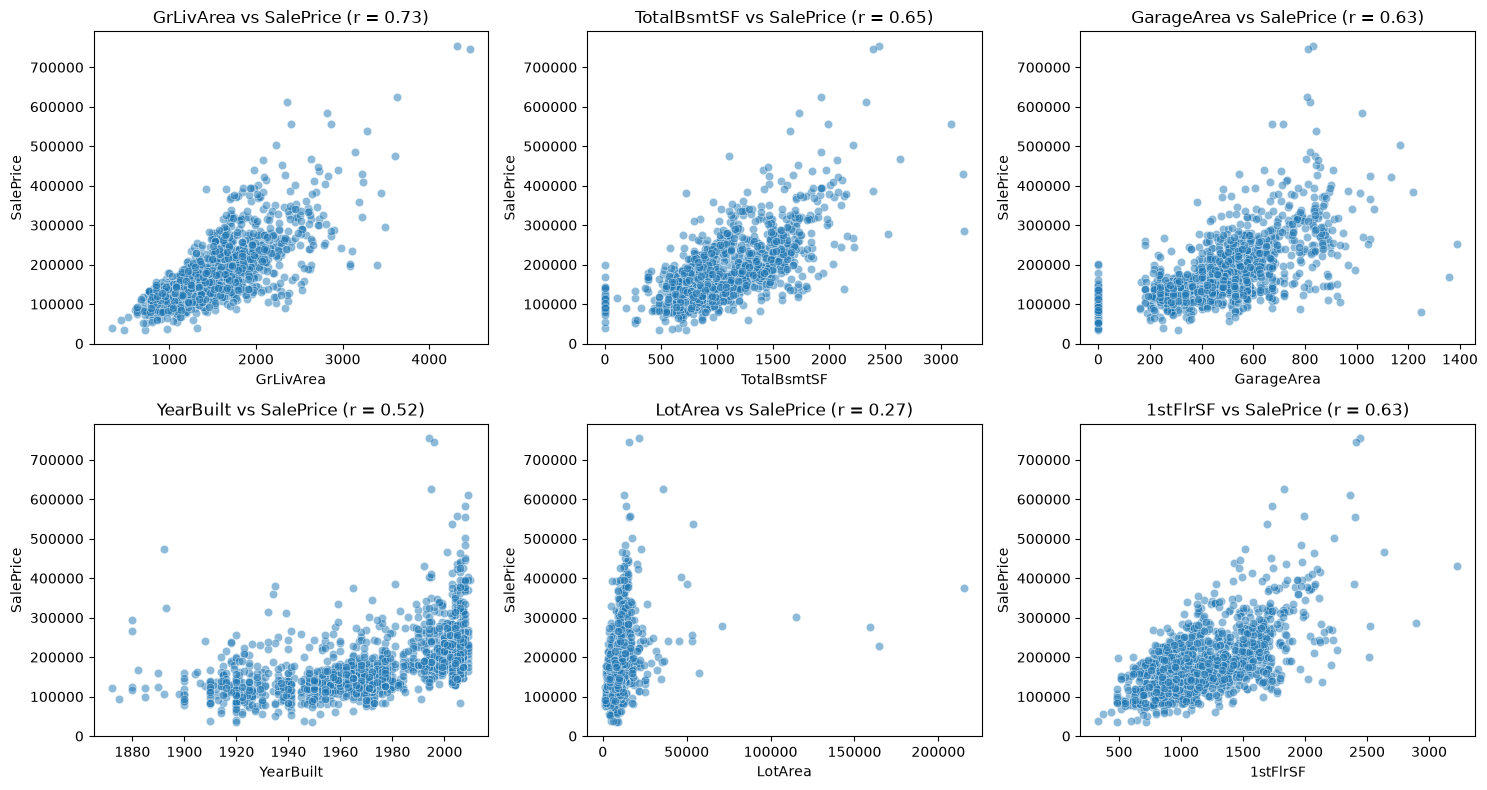

In [19]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for a, c in zip(ax.flat, ['GrLivArea', 'TotalBsmtSF', 'GarageArea', 'YearBuilt', 'LotArea', '1stFlrSF']):
    sns.scatterplot(data=tr, x=c, y='SalePrice', ax=a, alpha=0.5)
    a.set_title(f'{c} vs SalePrice (r = {tr[c].corr(tr.SalePrice):.2f})')
plt.tight_layout(); plt.savefig('numeric_vs_price.png', dpi=120); plt.show()

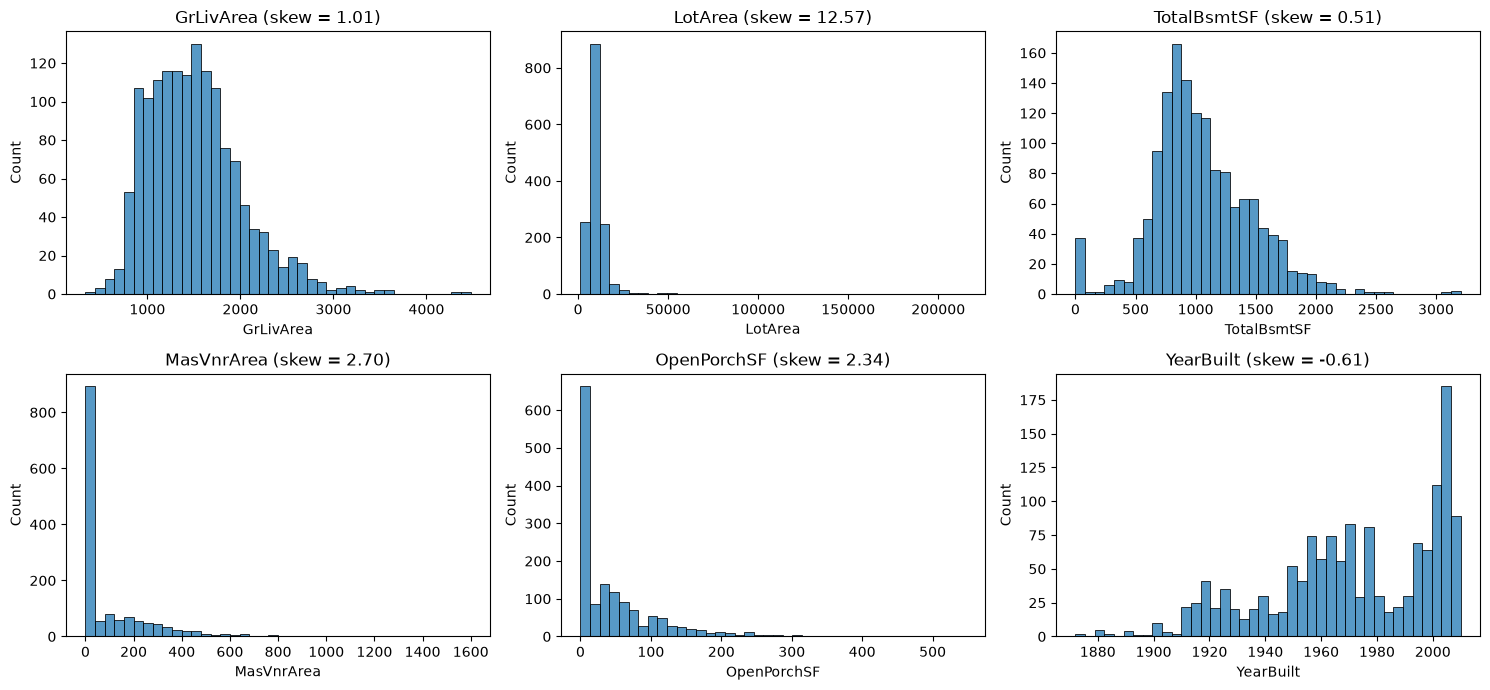

In [20]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.flat, ['GrLivArea', 'LotArea', 'TotalBsmtSF', 'MasVnrArea', 'OpenPorchSF', 'YearBuilt']):
    sns.histplot(tr[c], ax=a, bins=40); a.set_title(f'{c} (skew = {tr[c].skew():.2f})')
plt.tight_layout(); plt.savefig('numeric_distributions.png', dpi=120); plt.show()

### Categorical features

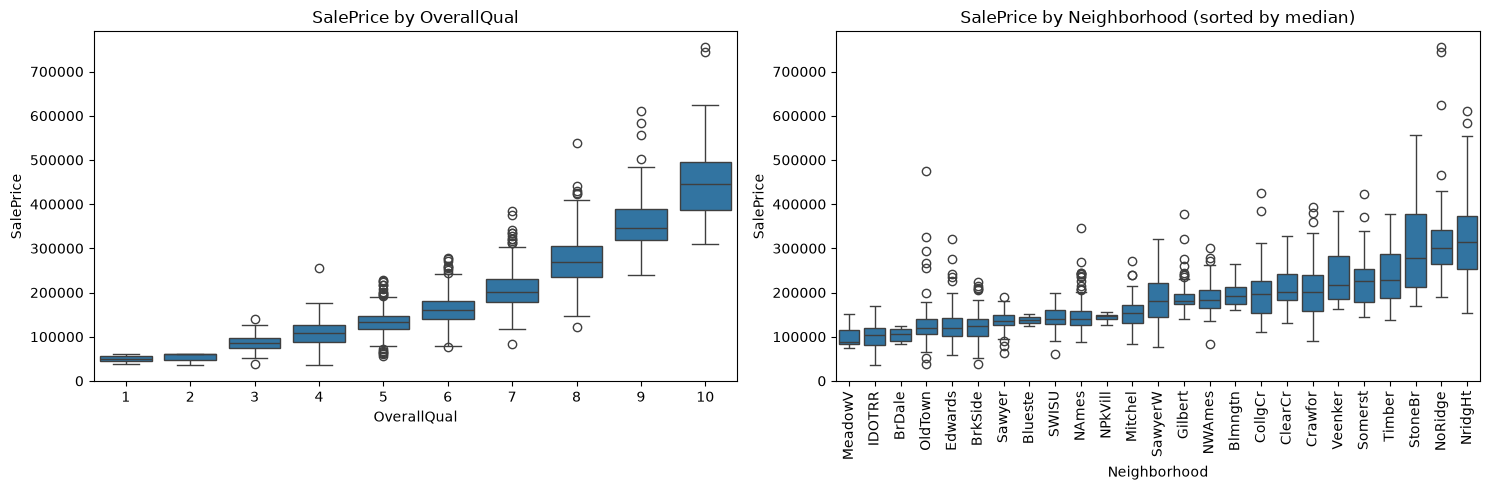

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=tr, x='OverallQual', y='SalePrice', ax=ax[0]); ax[0].set_title('SalePrice by OverallQual')
order = tr.groupby('Neighborhood')['SalePrice'].median().sort_values().index
sns.boxplot(data=tr, x='Neighborhood', y='SalePrice', order=order, ax=ax[1])
ax[1].tick_params(axis='x', rotation=90); ax[1].set_title('SalePrice by Neighborhood (sorted by median)')
plt.tight_layout(); plt.savefig('categorical_vs_price.png', dpi=120); plt.show()

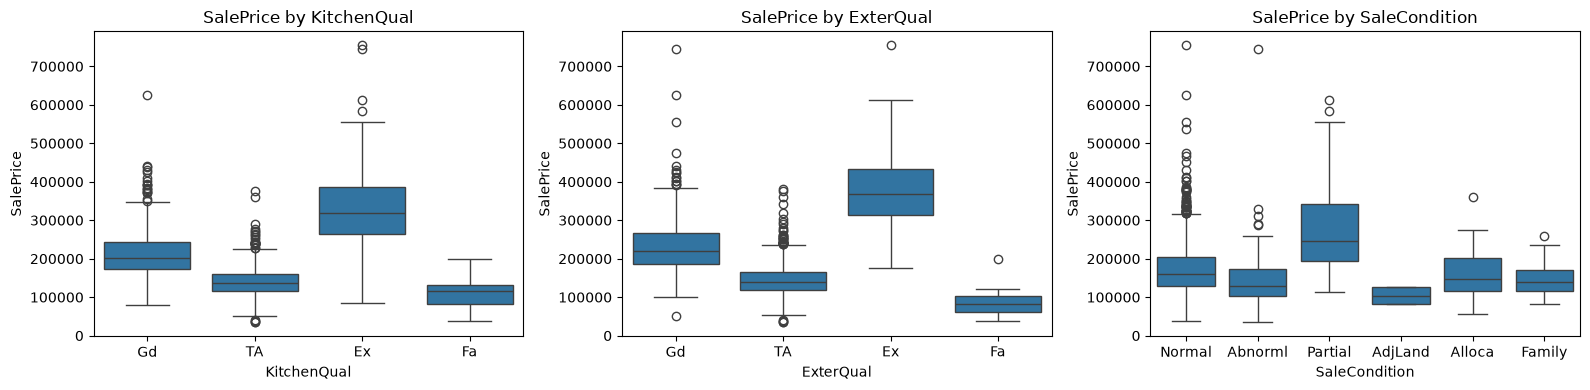

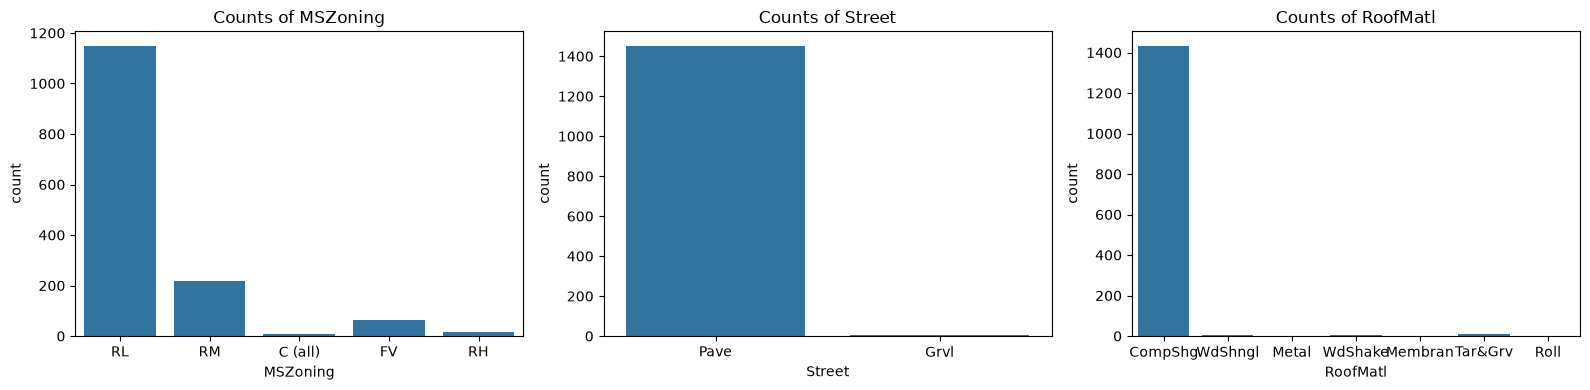

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['KitchenQual', 'ExterQual', 'SaleCondition']):
    sns.boxplot(data=tr, x=c, y='SalePrice', ax=a); a.set_title(f'SalePrice by {c}')
plt.tight_layout(); plt.savefig('quality_vs_price.png', dpi=120); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['MSZoning', 'Street', 'RoofMatl']):
    sns.countplot(data=tr, x=c, ax=a); a.set_title(f'Counts of {c}')
plt.tight_layout(); plt.show()

Quality ratings (Ex > Gd > TA > Fa) have a clear order, so we encode them as numbers 0–5. Some columns (Street, RoofMatl) are almost constant and carry little information.

## B6 New features

In [23]:
def add_features(df):
    df = df.copy()
    df['TotalSF']      = df['TotalBsmtSF'] + df['1stFlrSF'] + df['2ndFlrSF']
    df['TotalBath']    = df['FullBath'] + 0.5*df['HalfBath'] + df['BsmtFullBath'] + 0.5*df['BsmtHalfBath']
    df['HouseAge']     = df['YrSold'] - df['YearBuilt']
    df['RemodAge']     = df['YrSold'] - df['YearRemodAdd']
    df['TotalPorchSF'] = df['OpenPorchSF'] + df['EnclosedPorch'] + df['3SsnPorch'] + df['ScreenPorch'] + df['WoodDeckSF']
    df['QualxSF']      = df['OverallQual'] * df['GrLivArea']
    df['HasPool']      = (df['PoolArea'] > 0).astype(int)
    df['HasGarage']    = (df['GarageArea'] > 0).astype(int)
    df['Has2ndFloor']  = (df['2ndFlrSF'] > 0).astype(int)
    return df

base_data = all_data.copy()
all_data = add_features(all_data)
new_cols = ['TotalSF', 'TotalBath', 'HouseAge', 'RemodAge', 'TotalPorchSF', 'QualxSF']

**Evidence 1: correlation with log(SalePrice).** Each new feature should correlate more strongly than its parts.

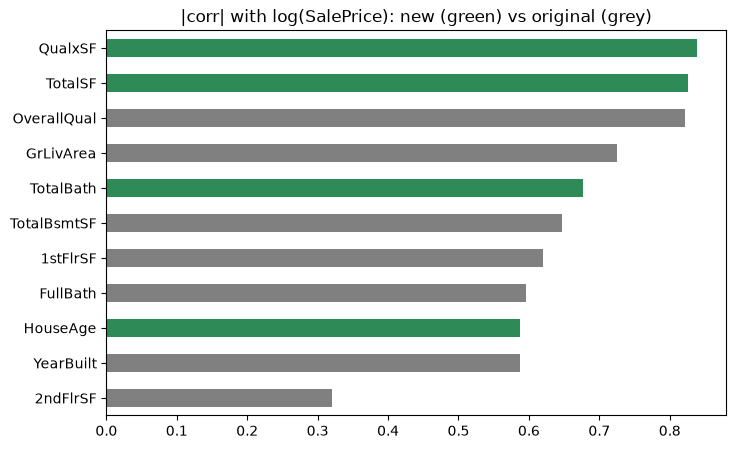

QualxSF        0.838445
TotalSF        0.825326
OverallQual    0.821405
GrLivArea      0.725211
TotalBath      0.676678
TotalBsmtSF    0.647563
1stFlrSF       0.620500
FullBath       0.595899
HouseAge       0.587767
YearBuilt      0.587043
2ndFlrSF       0.319953
dtype: float64

In [24]:
tr_new = all_data.iloc[:n_train]
comp = ['TotalSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'TotalBath', 'FullBath',
        'HouseAge', 'YearBuilt', 'QualxSF', 'OverallQual', 'GrLivArea']
corr = tr_new[comp].corrwith(y).abs().sort_values()
colors = ['seagreen' if c in new_cols else 'grey' for c in corr.index]
corr.plot.barh(color=colors, figsize=(8, 5)); plt.title('|corr| with log(SalePrice): new (green) vs original (grey)')
plt.savefig('new_features_corr.png', dpi=120, bbox_inches='tight'); plt.show()
corr.sort_values(ascending=False)

In [25]:
from sklearn.linear_model import Lasso
from sklearn.ensemble import GradientBoostingRegressor

def quick_encode(df):
    d = df.drop(columns=['Id']).copy()
    for c in ['MSSubClass', 'MoSold', 'YrSold']: d[c] = d[c].astype(str)
    num = [c for c in d.select_dtypes(include=np.number) if d[c].nunique() > 10 and d[c].min() >= 0]
    sk = d.iloc[:n_train][num].skew(); sk = sk[sk.abs() > 0.75].index
    d[sk] = np.log1p(d[sk])
    return pd.get_dummies(d).astype(float).iloc[:n_train]

kf = KFold(5, shuffle=True, random_state=42)
models = {'Lasso': make_pipeline(RobustScaler(), Lasso(alpha=0.0005, max_iter=50000)),
          'GradientBoosting': GradientBoostingRegressor(random_state=42)}
rows = []
for mname, m in models.items():
    for name, d in [('without', base_data), ('with', all_data)]:
        s = -cross_val_score(m, quick_encode(d), y, cv=kf, scoring='neg_root_mean_squared_error')
        rows.append({'model': mname, 'new features': name, 'CV RMSE': round(s.mean(), 4)})
pd.DataFrame(rows).pivot(index='model', columns='new features', values='CV RMSE')

new features,with,without
model,,
GradientBoosting,0.1230,0.1234
Lasso,0.1098,0.1099


**Evidence 3: feature importance.** Does the tree model actually use the new columns?

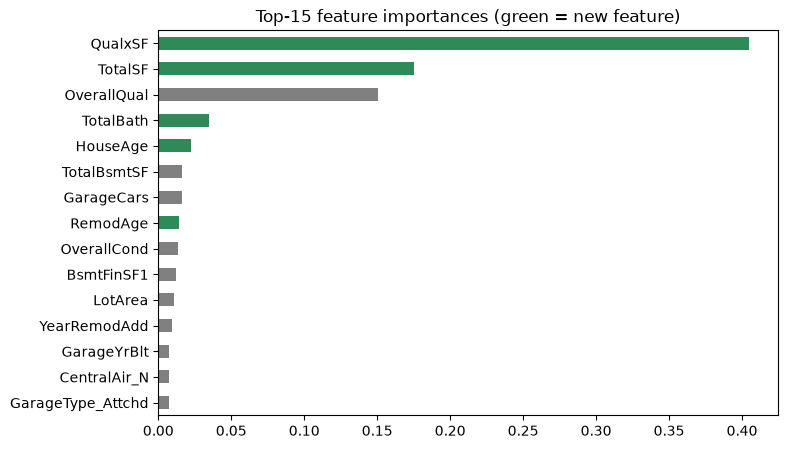

In [26]:
gb = GradientBoostingRegressor(random_state=42).fit(quick_encode(all_data), y)
imp = pd.Series(gb.feature_importances_, index=quick_encode(all_data).columns).sort_values(ascending=False)[:15]
imp.sort_values().plot.barh(color=['seagreen' if c in new_cols else 'grey' for c in imp.sort_values().index], figsize=(8, 5))
plt.title('Top-15 feature importances (green = new feature)')
plt.savefig('new_features_importance.png', dpi=120, bbox_inches='tight'); plt.show()

## B7 Select and encode

In [27]:

drop_cols = ['Id', 'GarageArea', 'GarageYrBlt', 'PoolQC', 'PoolArea', 'Street', 'MiscFeature', 'MiscVal']
all_data = all_data.drop(columns=drop_cols)

for c in ['MSSubClass', 'MoSold', 'YrSold']:
    all_data[c] = all_data[c].astype(str)

qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}
for c in ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC',
          'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']:
    all_data[c] = all_data[c].map(qual_map)
all_data['BsmtExposure'] = all_data['BsmtExposure'].map({'None': 0, 'No': 1, 'Mn': 2, 'Av': 3, 'Gd': 4})
fin = {'None': 0, 'Unf': 1, 'LwQ': 2, 'Rec': 3, 'BLQ': 4, 'ALQ': 5, 'GLQ': 6}
all_data['BsmtFinType1'] = all_data['BsmtFinType1'].map(fin)
all_data['BsmtFinType2'] = all_data['BsmtFinType2'].map(fin)
all_data['GarageFinish'] = all_data['GarageFinish'].map({'None': 0, 'Unf': 1, 'RFn': 2, 'Fin': 3})

num_cols = all_data.select_dtypes(include=np.number).columns
num_cols = [c for c in num_cols if all_data[c].nunique() > 10 and all_data[c].min() >= 0]
skew = all_data.iloc[:n_train][num_cols].skew()
skewed = skew[skew.abs() > 0.75].index
all_data[skewed] = np.log1p(all_data[skewed])
print(f'Log-transformed {len(skewed)} skewed features:', list(skewed))

all_data = pd.get_dummies(all_data).astype(float)
print('Final feature count:', all_data.shape[1])
assert all_data.isnull().sum().sum() == 0

Log-transformed 18 skewed features: ['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'TotalSF', 'TotalPorchSF', 'QualxSF']
Final feature count: 267


In [28]:
train_proc = all_data.iloc[:n_train].copy(); train_proc['SalePrice'] = y.values
test_proc  = all_data.iloc[n_train:].copy(); test_proc.insert(0, 'Id', test_ids.values)
train_proc.to_csv('train_processed.csv', index=False)
test_proc.to_csv('test_processed.csv', index=False)
print('Saved:', train_proc.shape, test_proc.shape)

Saved: (1458, 268) (1459, 268)
